# 02 – Hyperparameter tuning (Part 1)

This notebook tunes the hyperparameters of our recommenders on the **validation split** of MovieLens 1M.

**Protocol**
- All models are trained on `train` and scored on `val` (temporal split, see `src/data/splitting.py`).
- Hyperparameters are chosen by **NDCG@10** on validation; Precision@10, Recall@10 and catalogue coverage are recorded alongside.
- The **test split is never touched here.** The final evaluation (train on train(+val) with the chosen configs, evaluate once on test) belongs to `run_all.py`.

Models (after reference bounds for a random and a perfect ranker in section 0):
1. **MostPopular**: small grid over variants (all-time vs. recent window, all ratings vs. only positive).
2. **ItemKNN**: Optuna search over neighbourhood size `k`, similarity measure and significance weighting `gamma`.

In [1]:
import os
import sys
import time
from pathlib import Path

import yaml

# Works whether the notebook is started from the repo root or from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

cfg = yaml.safe_load((ROOT / "config.yaml").read_text())
DATA_DIR = Path(os.environ.get("DATA_DIR", ROOT / "data" / "ml-1m"))
print("ROOT:", ROOT)
print("DATA_DIR:", DATA_DIR)

ROOT: /home/jindra/Documents/DATA.ML.360-2026-2027-1_group16
DATA_DIR: /home/jindra/Documents/DATA.ML.360-2026-2027-1_group16/data/ml-1m


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd

from src.data.splitting import split
from src.evaluation import evaluate_recommender
from src.model import Dataset, ItemKNN, MostPopular

optuna.logging.set_verbosity(optuna.logging.WARNING)  # we print our own one-line progress per trial

/home/jindra/Documents/DATA.ML.360-2026-2027-1_group16/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Settings

Runtime guide (one full validation evaluation; ~490 of the ~1,100 evaluated users are known from train,
the kNN models return nothing for the others instantly): MostPopular < 1 s, ItemKNN cosine ~170 s,
ItemKNN pearson ~290 s. So with all validation users, 30 ItemKNN trials take roughly **1.5–2.5 hours**.

For a quick run, set `MAX_USERS` to a small number (e.g. 50). The trial count and `MAX_USERS` can also be
overridden by environment variables without editing the notebook:
`TUNING_N_TRIALS_ITEMKNN`, `TUNING_MAX_USERS`.

In [3]:
def _env_int(name, default):
    """Read an int from an environment variable; empty/'none' means None."""
    value = os.environ.get(name)
    if value is None:
        return default
    return None if value.strip().lower() in ("", "none") else int(value)

K = 10                   # cut-off for Precision@K, Recall@K, NDCG@K and coverage
RELEVANCE_THRESHOLD = 4  # a validation rating >= this counts as relevant
SEED = 42                # seeds the Optuna sampler and the user subsample

N_TRIALS_ITEMKNN = _env_int("TUNING_N_TRIALS_ITEMKNN", 30)  # ~1.5–2.5 h with all users
MAX_USERS = _env_int("TUNING_MAX_USERS", None)              # None = all validation users

print(f"K={K}, threshold={RELEVANCE_THRESHOLD}, seed={SEED}")
print(f"trials: ItemKNN={N_TRIALS_ITEMKNN}, MAX_USERS={MAX_USERS}")

K=10, threshold=4, seed=42
trials: ItemKNN=30, MAX_USERS=None


## Data and split

In [4]:
ds = Dataset.from_config(DATA_DIR, cfg["load"])
s = split(ds, cfg["split"])
print(s.summary())

train   800168 rows  2000-04-25 -> 2000-12-02
val     100020 rows  2000-12-02 -> 2000-12-29
test    100021 rows  2000-12-29 -> 2003-02-28


**Catalogue.** We rank against, and measure coverage over, the *full* catalogue: all movies listed in
`movies.dat` (3,883), not only the movies that happen to appear in the training ratings. Movies with no training ratings simply can never
be recommended, which lowers coverage – an honest reflection of the cold-start problem.

In [5]:
CATALOGUE = set(ds.movies["item_id"])
print("catalogue size:", len(CATALOGUE))

catalogue size: 3883


## Validation users and the `evaluate` helper

`evaluate_recommender` scores **every** user who has at least one relevant (rating >= threshold) validation
rating, including users with no train ratings (cold start). A model that cannot recommend for a new user
returns an empty list and scores 0 for that user, so the main numbers include how well a model handles cold
start. The returned dict also has the metrics separately for `_warm` (users in train) and `_cold` users.

If `MAX_USERS` is set, we sample that many users (fixed seed) and keep only their validation ratings – the same
users are then used for every model, so results stay comparable.

In [6]:
positive_val_users = set(s.val.ratings.loc[s.val.ratings["rating"] >= RELEVANCE_THRESHOLD, "user_id"])
eligible_users = sorted(positive_val_users)

if MAX_USERS is not None and MAX_USERS < len(eligible_users):
    rng = np.random.default_rng(SEED)
    eval_users = sorted(rng.choice(eligible_users, size=MAX_USERS, replace=False).tolist())
else:
    eval_users = eligible_users

VAL_RATINGS = s.val.ratings[s.val.ratings["user_id"].isin(eval_users)]
n_cold = len(set(eval_users) - set(s.train.ratings["user_id"]))
print(f"eligible validation users: {len(eligible_users)}, evaluated: {len(eval_users)} "
      f"(of which {n_cold} cold-start, i.e. not in train)")

eligible validation users: 1103, evaluated: 1103 (of which 611 cold-start, i.e. not in train)


In [7]:
def evaluate(model):
    """Train `model` on the train split and return its validation metrics (dict) plus runtime."""
    start = time.time()
    model.train(s.train)
    metrics = evaluate_recommender(model, s.train.ratings, VAL_RATINGS, CATALOGUE,
                                   k=K, threshold=RELEVANCE_THRESHOLD)
    metrics["seconds"] = round(time.time() - start, 1)
    return metrics

## 0. Reference bounds: random and perfect ranker

Ranking metrics have no natural scale, so we compute a floor and a ceiling on exactly the same users,
relevance threshold and metric code as the models:

- **Random**: 10 random catalogue movies the user has not rated in train (fixed seed). Any real model should
  be far above this.
- **Perfect ranker**: recommends the user's relevant validation movies first (it "knows the answers").
  NDCG@10 is 1 by definition, but **Precision@10 is not**: a user with only 3 relevant movies can get at most
  3/10. So the perfect-ranker precision is the highest precision achievable on this split, and the models
  should be read relative to it, not relative to 1.

In [8]:
from src.evaluation import evaluate_model

# Relevant validation movies per evaluated user (same definition as evaluate_recommender)
positive_val = VAL_RATINGS[VAL_RATINGS["rating"] >= RELEVANCE_THRESHOLD]
relevant = positive_val.groupby("user_id")["item_id"].apply(set).to_dict()
relevant = {user: relevant[user] for user in eval_users}
seen = s.train.ratings.groupby("user_id")["item_id"].apply(set)

rng = np.random.default_rng(SEED)
catalogue = np.array(sorted(CATALOGUE))
random_recs = {user: rng.choice(np.setdiff1d(catalogue, list(seen.get(user, set()))), size=K, replace=False).tolist()
               for user in eval_users}
perfect_recs = {user: sorted(relevant[user])[:K] for user in eval_users}

n_relevant = pd.Series({user: len(items) for user, items in relevant.items()})
print(f"relevant movies per user: median {n_relevant.median():.0f}, "
      f"users with fewer than {K}: {(n_relevant < K).mean():.0%}")

bounds = pd.DataFrame([
    {"model": "Random", **evaluate_model(random_recs, relevant, CATALOGUE, K)},
    {"model": "Perfect ranker", **evaluate_model(perfect_recs, relevant, CATALOGUE, K)},
])
bounds

relevant movies per user: median 26, users with fewer than 10: 27%


,model,precision,recall,ndcg,coverage,users_evaluated
0,Random,0.012330,0.00266,0.012297,0.940510,1103
1,Perfect ranker,0.820943,0.49548,1.000000,0.345352,1103


## 1. MostPopular

Grid: `only_positive` ∈ {False, True} × `window_days` ∈ {None (all-time), 7, 30, 90}.
`window_days` counts popularity only over the last N days of the training period.

In [9]:
rows = []
for only_positive in [False, True]:
    for window_days in [None, 7, 30, 90]:
        model = MostPopular(only_positive=only_positive, positive_threshold=RELEVANCE_THRESHOLD,
                            window_days=window_days)
        rows.append({"only_positive": only_positive, "window_days": window_days, **evaluate(model)})

mostpop_results = pd.DataFrame(rows).sort_values("ndcg", ascending=False).reset_index(drop=True)
mostpop_results["window_days"] = mostpop_results["window_days"].astype("Int64")  # <NA> = all-time
mostpop_results

,only_positive,window_days,precision,recall,ndcg,coverage,users_evaluated,precision_warm,recall_warm,ndcg_warm,users_evaluated_warm,precision_cold,recall_cold,ndcg_cold,users_evaluated_cold,seconds
0,True,7,0.243064,0.074950,0.265264,0.028071,1103,0.116870,0.078457,0.138538,492,0.344681,0.072125,0.367309,611,0.3
1,True,30,0.241070,0.063934,0.260472,0.029874,1103,0.110772,0.053261,0.125717,492,0.345990,0.072529,0.368981,611,0.3
2,True,<NA>,0.240979,0.060738,0.260403,0.031161,1103,0.113618,0.047749,0.126124,492,0.343535,0.071197,0.368529,611,0.3
3,True,90,0.238985,0.062616,0.258638,0.029874,1103,0.111992,0.052925,0.126171,492,0.341244,0.070420,0.365306,611,0.3
4,False,7,0.233726,0.078025,0.256679,0.027556,1103,0.110569,0.087704,0.136512,492,0.332897,0.070230,0.353441,611,0.3
5,False,<NA>,0.232729,0.058065,0.253826,0.033479,1103,0.104675,0.044278,0.118544,492,0.335843,0.069167,0.362760,611,0.4
6,False,90,0.231006,0.061591,0.248394,0.030131,1103,0.105285,0.052494,0.117983,492,0.332242,0.068917,0.353406,611,0.4
7,False,30,0.230734,0.062142,0.248126,0.029101,1103,0.104675,0.053728,0.117932,492,0.332242,0.068917,0.352963,611,0.3


## 2. ItemKNN (Optuna)

Objective: NDCG@10 on validation (maximise). Search space:
- `k` (neighbourhood size): integer, log-scale in [5, 200] – small values matter more than large ones;
- `similarity_measure`: cosine, pearson, jaccard;
- `gamma` (significance weighting; None = off): None, 10, 25, 50, 100.

We use Optuna's TPE sampler with a fixed seed. Precision, recall and coverage are stored on each trial as
`user_attrs` so we can report them later.

In [10]:
GAMMAS = [None, 10, 25, 50, 100]


def make_objective(model_class):
    """Optuna objective: build `model_class` from the suggested params, return validation NDCG."""
    def objective(trial):
        k = trial.suggest_int("k", 5, 200, log=True)
        similarity = trial.suggest_categorical("similarity_measure", ["cosine", "pearson", "jaccard"])
        # Optuna categorical choices must be simple values; None is allowed
        gamma = trial.suggest_categorical("gamma", GAMMAS)

        metrics = evaluate(model_class(k=k, similarity_measure=similarity, gamma=gamma))
        for name in ["precision", "recall", "coverage", "users_evaluated", "seconds",
                     "ndcg_warm", "ndcg_cold", "users_evaluated_cold"]:
            if name in metrics:  # no _cold metrics if a MAX_USERS sample has no cold users
                trial.set_user_attr(name, metrics[name])
        print(f"trial {trial.number:3d}: k={k:3d} sim={similarity:8s} gamma={str(gamma):4s} "
              f"-> ndcg={metrics['ndcg']:.4f} prec={metrics['precision']:.4f} "
              f"cov={metrics['coverage']:.3f} ({metrics['seconds']} s)")
        return metrics["ndcg"]
    return objective


def trials_table(study):
    """One row per finished trial: params + all metrics, best NDCG first."""
    df = study.trials_dataframe(attrs=("number", "value", "params", "user_attrs", "state"))
    df = df[df["state"] == "COMPLETE"].drop(columns="state")
    df = df.rename(columns=lambda c: c.replace("params_", "").replace("user_attrs_", ""))
    df = df.rename(columns={"value": "ndcg", "number": "trial"})
    df["gamma"] = df["gamma"].astype("Int64")  # <NA> = no significance weighting
    cols = ["trial", "k", "similarity_measure", "gamma", "ndcg", "ndcg_warm", "ndcg_cold", "precision",
            "recall", "coverage", "users_evaluated", "users_evaluated_cold", "seconds"]
    return df[[col for col in cols if col in df.columns]].sort_values("ndcg", ascending=False).reset_index(drop=True)


def plot_ndcg_vs_k(table, title):
    fig, ax = plt.subplots(figsize=(7, 4))
    for similarity, group in table.groupby("similarity_measure"):
        ax.scatter(group["k"], group["ndcg"], label=similarity, alpha=0.8)
    ax.set_xscale("log")
    ax.set_xlabel("neighbourhood size k (log scale)")
    ax.set_ylabel(f"NDCG@{K} (validation)")
    ax.set_title(title)
    ax.legend(title="similarity")
    ax.grid(alpha=0.3)
    plt.show()


def best_per_similarity(table):
    """Best trial for each similarity measure (to justify the similarity choice in the report)."""
    return (table.sort_values("ndcg", ascending=False)
                 .groupby("similarity_measure", as_index=False).head(1)
                 .reset_index(drop=True))

In [11]:
itemknn_study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
itemknn_study.optimize(make_objective(ItemKNN), n_trials=N_TRIALS_ITEMKNN)

trial   0: k= 19 sim=cosine   gamma=50   -> ndcg=0.0256 prec=0.0226 cov=0.090 (172.9 s)
trial   1: k= 66 sim=pearson  gamma=100  -> ndcg=0.0227 prec=0.0201 cov=0.065 (316.0 s)
trial   2: k= 23 sim=pearson  gamma=50   -> ndcg=0.0228 prec=0.0208 cov=0.087 (292.4 s)
trial   3: k= 32 sim=jaccard  gamma=50   -> ndcg=0.0235 prec=0.0209 cov=0.071 (166.7 s)
trial   4: k= 14 sim=pearson  gamma=50   -> ndcg=0.0214 prec=0.0197 cov=0.110 (288.8 s)
trial   5: k= 56 sim=jaccard  gamma=10   -> ndcg=0.0237 prec=0.0214 cov=0.058 (154.8 s)
trial   6: k= 44 sim=cosine   gamma=100  -> ndcg=0.0236 prec=0.0208 cov=0.054 (152.8 s)
trial   7: k= 17 sim=pearson  gamma=25   -> ndcg=0.0219 prec=0.0197 cov=0.099 (266.7 s)
trial   8: k=  5 sim=cosine   gamma=100  -> ndcg=0.0222 prec=0.0201 cov=0.163 (150.8 s)
trial   9: k= 48 sim=cosine   gamma=50   -> ndcg=0.0234 prec=0.0209 cov=0.052 (151.0 s)
trial  10: k=116 sim=cosine   gamma=None -> ndcg=0.0214 prec=0.0198 cov=0.034 (99.5 s)
trial  11: k=106 sim=jaccard  gam

In [12]:
itemknn_trials = trials_table(itemknn_study)
print("best params:", itemknn_study.best_params, "ndcg:", round(itemknn_study.best_value, 4))
itemknn_trials

best params: {'k': 13, 'similarity_measure': 'cosine', 'gamma': None} ndcg: 0.0277


,trial,k,similarity_measure,gamma,ndcg,ndcg_warm,ndcg_cold,precision,recall,coverage,users_evaluated,users_evaluated_cold,seconds
0,21,13,cosine,<NA>,0.027676,0.062047,0.0,0.023481,0.012896,0.117693,1103,611,101.4
1,16,20,cosine,<NA>,0.027283,0.061164,0.0,0.022393,0.015559,0.094257,1103,611,100.3
2,14,15,jaccard,10,0.027166,0.060903,0.0,0.022665,0.015262,0.112799,1103,611,165.4
3,22,10,cosine,<NA>,0.026417,0.059225,0.0,0.022212,0.013750,0.138810,1103,611,103.5
4,17,16,cosine,<NA>,0.026414,0.059217,0.0,0.022393,0.013150,0.104301,1103,611,104.3
5,28,10,jaccard,100,0.025920,0.058110,0.0,0.021215,0.014344,0.134690,1103,611,176.4
6,18,27,cosine,<NA>,0.025589,0.057368,0.0,0.021850,0.017024,0.078032,1103,611,102.1
7,0,19,cosine,50,0.025581,0.057349,0.0,0.022575,0.016033,0.090136,1103,611,172.9
8,13,12,jaccard,10,0.025540,0.057256,0.0,0.021759,0.014922,0.130054,1103,611,165.9
9,23,21,jaccard,10,0.025368,0.056873,0.0,0.021124,0.013678,0.093227,1103,611,165.3


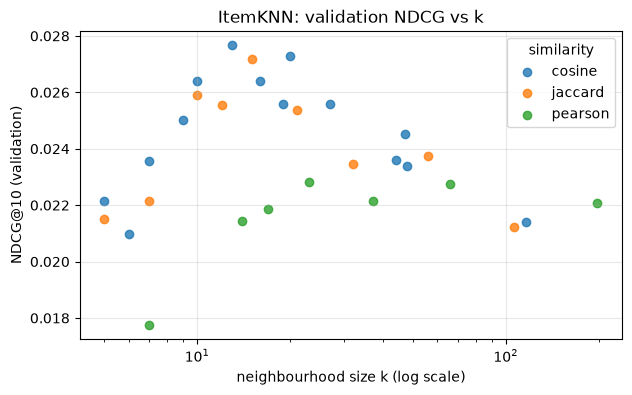

,trial,k,similarity_measure,gamma,ndcg,ndcg_warm,ndcg_cold,precision,recall,coverage,users_evaluated,users_evaluated_cold,seconds
0,21,13,cosine,<NA>,0.027676,0.062047,0.0,0.023481,0.012896,0.117693,1103,611,101.4
1,14,15,jaccard,10,0.027166,0.060903,0.0,0.022665,0.015262,0.112799,1103,611,165.4
2,2,23,pearson,50,0.022836,0.051195,0.0,0.020762,0.012506,0.087304,1103,611,292.4


In [13]:
plot_ndcg_vs_k(itemknn_trials, "ItemKNN: validation NDCG vs k")
best_per_similarity(itemknn_trials)

## 3. Summary

Best configuration per model on validation, with all four metrics. Below is a YAML snippet with the chosen
configs that can be pasted into `config.yaml` (this notebook does not modify it).

In [14]:
metric_cols = ["ndcg", "precision", "recall", "coverage"]
# NDCG separately for users known from train and new users (if the evaluated users include both)
metric_cols += [col for col in ["ndcg_warm", "ndcg_cold"]
                if all(col in table for table in [mostpop_results, itemknn_trials])]
best_mostpop = mostpop_results.iloc[0]
best_item = itemknn_trials.iloc[0]

summary = pd.DataFrame([
    {"model": "MostPopular",
     "config": f"only_positive={best_mostpop['only_positive']}, window_days={best_mostpop['window_days']}",
     **best_mostpop[metric_cols].to_dict()},
    {"model": "ItemKNN",
     "config": f"k={best_item['k']}, sim={best_item['similarity_measure']}, gamma={best_item['gamma']}",
     **best_item[metric_cols].to_dict()},
])
# floor and ceiling from section 0, for reading the numbers above
summary = pd.concat([summary, bounds.reindex(columns=["model", *metric_cols]).assign(config="reference bound")],
                    ignore_index=True)
print(f"validation users evaluated: {len(eval_users)} (MAX_USERS={MAX_USERS})")
summary

validation users evaluated: 1103 (MAX_USERS=None)


,model,config,ndcg,precision,recall,coverage,ndcg_warm,ndcg_cold
0,MostPopular,"only_positive=True, window_days=7",0.265264,0.243064,0.074950,0.028071,0.138538,0.367309
1,ItemKNN,"k=13, sim=cosine, gamma=<NA>",0.027676,0.023481,0.012896,0.117693,0.062047,0.000000
2,Random,reference bound,0.012297,0.012330,0.002660,0.940510,NaN,NaN
3,Perfect ranker,reference bound,1.000000,0.820943,0.495480,0.345352,NaN,NaN


In [15]:
def _clean(value):
    """Convert numpy / NaN values to plain Python for YAML."""
    if pd.isna(value):  # None / NaN / <NA> = "off" (all-time window, no significance weighting)
        return None
    return value.item() if hasattr(value, "item") else value

window = _clean(best_mostpop["window_days"])
snippet = {"models": {
    "most_popular": {"only_positive": bool(best_mostpop["only_positive"]),
                     "positive_threshold": RELEVANCE_THRESHOLD,
                     "window_days": None if window is None else int(window)},
    "item_knn": {"k": int(best_item["k"]),
                 "similarity_measure": str(best_item["similarity_measure"]),
                 "gamma": _clean(best_item["gamma"])},
}}
print(yaml.safe_dump(snippet, sort_keys=False))

models:
  most_popular:
    only_positive: true
    positive_threshold: 4
    window_days: 7
  item_knn:
    k: 13
    similarity_measure: cosine
    gamma: null



## 4. ItemKNN: `min_support` (added after the main run)

Section 2 ran with the default `min_support=20`: `rank` only recommends movies with at least that many train
ratings (see the comment in `_KNN.rank` for why the filter exists). It was not part of the Optuna search, so
here we vary it for the three best configurations of section 2 and keep their other parameters fixed.
`min_support` only decides which movies are candidates and does not change the similarities, so we do not
expect it to interact strongly with `k`, the similarity measure or `gamma`. `min_support=1` means no filter.

The three configurations are written out explicitly instead of being read from `itemknn_trials`, so this
section only needs the setup cells above and not the 2-hour Optuna search.
Runtime: 21 evaluations, roughly 40–50 minutes with all validation users.

In [16]:
TOP_CONFIGS = [  # the three best trials of section 2 (trials 21, 16 and 14)
    {"k": 13, "similarity_measure": "cosine", "gamma": None},
    {"k": 20, "similarity_measure": "cosine", "gamma": None},
    {"k": 15, "similarity_measure": "jaccard", "gamma": 10},
]
MIN_SUPPORTS = [1, 5, 10, 20, 50, 100, 200]

rows = []
for config in TOP_CONFIGS:
    for min_support in MIN_SUPPORTS:
        metrics = evaluate(ItemKNN(**config, min_support=min_support))
        label = f"k={config['k']}, {config['similarity_measure']}, gamma={config['gamma']}"
        rows.append({"config": label, **config, "min_support": min_support, **metrics})
        print(f"k={config['k']:3d} sim={config['similarity_measure']:8s} gamma={str(config['gamma']):4s} "
              f"min_support={min_support:3d} -> ndcg={metrics['ndcg']:.4f} "
              f"prec={metrics['precision']:.4f} cov={metrics['coverage']:.3f} ({metrics['seconds']} s)")

min_support_results = pd.DataFrame(rows)

k= 13 sim=cosine   gamma=None min_support=  1 -> ndcg=0.0021 prec=0.0027 cov=0.050 (108.8 s)
k= 13 sim=cosine   gamma=None min_support=  5 -> ndcg=0.0198 prec=0.0181 cov=0.112 (104.9 s)
k= 13 sim=cosine   gamma=None min_support= 10 -> ndcg=0.0260 prec=0.0224 cov=0.118 (105.1 s)
k= 13 sim=cosine   gamma=None min_support= 20 -> ndcg=0.0277 prec=0.0235 cov=0.118 (108.8 s)
k= 13 sim=cosine   gamma=None min_support= 50 -> ndcg=0.0284 prec=0.0240 cov=0.112 (100.4 s)
k= 13 sim=cosine   gamma=None min_support=100 -> ndcg=0.0293 prec=0.0258 cov=0.109 (93.7 s)
k= 13 sim=cosine   gamma=None min_support=200 -> ndcg=0.0306 prec=0.0270 cov=0.095 (84.4 s)
k= 20 sim=cosine   gamma=None min_support=  1 -> ndcg=0.0014 prec=0.0016 cov=0.041 (117.5 s)
k= 20 sim=cosine   gamma=None min_support=  5 -> ndcg=0.0188 prec=0.0174 cov=0.086 (102.3 s)
k= 20 sim=cosine   gamma=None min_support= 10 -> ndcg=0.0256 prec=0.0217 cov=0.095 (112.9 s)
k= 20 sim=cosine   gamma=None min_support= 20 -> ndcg=0.0273 prec=0.0224

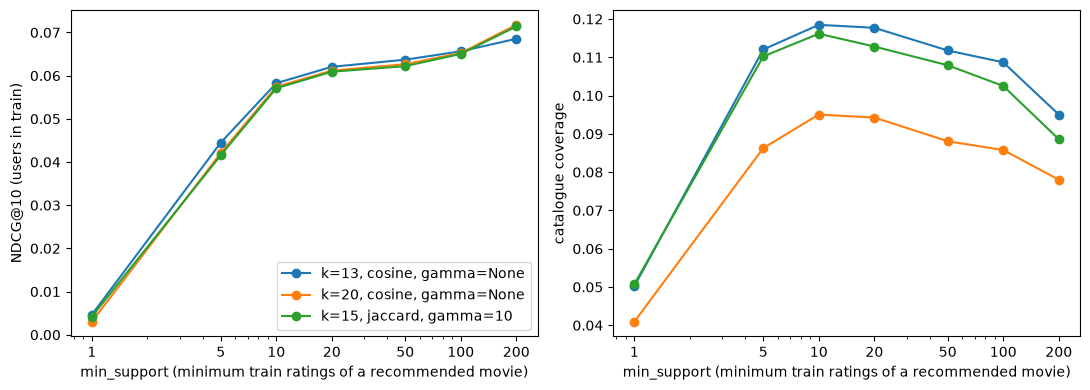

ndcg                           \
config      k=13, cosine, gamma=None k=20, cosine, gamma=None   
min_support                                                     
1                           0.002072                 0.001352   
5                           0.019848                 0.018769   
10                          0.025984                 0.025620   
20                          0.027676                 0.027283   
50                          0.028411                 0.027946   
100                         0.029277                 0.029097   
200                         0.030570                 0.032012   

                                                   ndcg_warm  \
config      k=15, jaccard, gamma=10 k=13, cosine, gamma=None   
min_support                                                    
1                          0.001872                 0.004644   
5                          0.018545                 0.044497   
10                         0.025465                 0.058252   
20                         0.027166                 0.062047   
50                         0.027746                 0.063694   
100                        0.029006                 0.065636   
200                        0.031846                 0.068534   

                                                              \
config      k=20, cosine, gamma=None k=15, jaccard, gamma=10   
min_support                                                    
1                           0.003030                0.004197   
5                           0.042077                0.041575   
10                          0.057436                0.057089   
20                          0.061164                0.060903   
50                          0.062652                0.062203   
100                         0.065232                0.065027   
200                         0.071766                0.071395   

                           precision                           \
config      k=13, cosine, gamma=None k=20, cosine, gamma=None   
min_support                                                     
1                           0.002720                 0.001632   
5                           0.018132                 0.017407   
10                          0.022393                 0.021668   
20                          0.023481                 0.022393   
50                          0.024025                 0.023300   
100                         0.025839                 0.025476   
200                         0.027017                 0.028196   

                                                      recall  \
config      k=15, jaccard, gamma=10 k=13, cosine, gamma=None   
min_support                                                    
1                          0.001813                 0.001176   
5                          0.016863                 0.010599   
10                         0.021306                 0.012404   
20                         0.022665                 0.012896   
50                         0.023300                 0.013262   
100                        0.024932                 0.012246   
200                        0.027833                 0.012506   

                                                              \
config      k=20, cosine, gamma=None k=15, jaccard, gamma=10   
min_support                                                    
1                           0.000715                0.002537   
5                           0.011431                0.012359   
10                          0.015377                0.014906   
20                          0.015559                0.015262   
50                          0.015812                0.015370   
100                         0.015173                0.014461   
200                         0.017255                0.016456   

                            coverage                           \
config      k=13, cosine, gamma=None k=20, cosine, gamma=None   
min_support                         

In [17]:
# NDCG on users known from train (the only ones ItemKNN can serve) and coverage, per min_support
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for config, group in min_support_results.groupby("config", sort=False):
    axes[0].plot(group["min_support"], group["ndcg_warm"], marker="o", label=config)
    axes[1].plot(group["min_support"], group["coverage"], marker="o", label=config)
for ax, metric in zip(axes, ["NDCG@10 (users in train)", "catalogue coverage"]):
    ax.set_xscale("log")
    ax.set_xticks(MIN_SUPPORTS, labels=[str(m) for m in MIN_SUPPORTS])
    ax.set_xlabel("min_support (minimum train ratings of a recommended movie)")
    ax.set_ylabel(metric)
axes[0].legend()
plt.tight_layout()
plt.show()

min_support_results.pivot_table(index="min_support", columns="config",
                                values=["ndcg", "ndcg_warm", "precision", "recall", "coverage"], sort=False)

In [18]:
best_min_support = min_support_results.sort_values("ndcg", ascending=False, kind="stable").iloc[0]
print("best ItemKNN config including min_support:")
print(best_min_support[["k", "similarity_measure", "gamma", "min_support",
                        "ndcg", "ndcg_warm", "precision", "recall", "coverage"]].to_string())

# Replaces the item_knn part of the YAML snippet in section 3, which was printed before min_support was tuned
print()
print(yaml.safe_dump({"models": {"item_knn": {
    "k": int(best_min_support["k"]),
    "similarity_measure": str(best_min_support["similarity_measure"]),
    "gamma": None if pd.isna(best_min_support["gamma"]) else int(best_min_support["gamma"]),
    "min_support": int(best_min_support["min_support"]),
}}}, sort_keys=False))

best ItemKNN config including min_support:
k                           20
similarity_measure      cosine
gamma                      NaN
min_support                200
ndcg                  0.032012
ndcg_warm             0.071766
precision             0.028196
recall                0.017255
coverage              0.078032

models:
  item_knn:
    k: 20
    similarity_measure: cosine
    gamma: null
    min_support: 200

